<pre style="font-size: 15px; line-height: 1.2;">
---
course_code: 02BMSBI24365
course_title: AI and ML in Bioinformatics
unit: Unit 2.3 & 2.4 — Applied Practicals (Lab Exercise 02)
scheduled_dates: Week 10 (Day 19)
document_type: Interactive Laboratory Practical
ai_tier: "Tier 3: AI Collaboration (Disclosed)"
---
</pre>

# 🧬 Lab Exercise 02: End-to-End Regression Pipeline & Continuous Disease Progression

<small><b>Course Code:</b> 02BMSBI24365 | <b>Unit 2:</b> Machine Learning Techniques | <b>Environment:</b> <code>gcu-aiml-bioinfo</code> | <b>AI Tier:</b> Tier 3: AI Collaboration (Disclosed)</small>

---

## Executive Summary & Laboratory Architecture

While diagnostic classification answers discrete questions (*Is this biopsy malignant or benign?*), many vital biological and clinical questions require predicting **continuous numerical endpoints**:
* *What is the patient's quantitative disease progression score one year following baseline examination?*
* *What is the minimum inhibitory concentration ($IC_{50}$) of a candidate targeted therapeutic?*
* *What is the biological aging delta derived from patient epigenetic DNA methylation clocks?*

In this practical, we implement an end-to-end, leak-free machine learning regression pipeline on a clinical cohort. We execute a rigorous data hygiene pass (deduplication, anomaly screening, median imputation), conduct exploratory data analysis (EDA), benchmark three complementary regression models (Ridge, Random Forest, Gradient Boosting) with thorough parameter and result analysis, and synthesize a master performance comparison table.

```text
┌────────────────────────────────────────────────────────────────────────────────────────┐
│                      9-STAGE SEQUENTIAL PIPELINE ARCHITECTURE                          │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ Stage 1: Clinical Problem Formulation & Continuous Prediction Stakes                   │
│ Stage 2: Raw Ingestion & Initial Data Quality Audit                                    │
│ Stage 3: Data Quality Pass (Deduplication, Anomaly Filtering, Median Imputation)       │
│ Stage 4: Exploratory Data Analysis (Target Skewness & Correlation Heatmap)             │
│ Stage 5: Leak-Free Preprocessing & Train/Test Partitioning                             │
│ Stage 6: Model 1 — Regularized Linear Regression (Ridge Baseline & Biomarker Weights)  │
│ Stage 7: Model 2 — Random Forest Regressor (Non-Linear Ensemble & Feature Importance)  │
│ Stage 8: Model 3 — Gradient Boosting Regressor (Sequential Residual Minimization)      │
│ Stage 9: Multi-Model Benchmark Synthesis & Comparative Performance Analysis            │
└────────────────────────────────────────────────────────────────────────────────────────┘
```


---
## Stage 0: Environment Initialization & Reproducible Seed


In [33]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing, models, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Matplotlib & Seaborn publication styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ Environment initialized successfully.")
print(f"✓ Python runtime: {sys.version.split()[0]} | Pandas: {pd.__version__}")


✓ Environment initialized successfully.
✓ Python runtime: 3.10.21 | Pandas: 2.3.3


---
## Stage 1: Clinical Problem Formulation & Mathematical Invariants

### 1. The Clinical Objective
We analyze an unscaled clinical cohort of patients diagnosed with diabetes mellitus ($n = 442$ baseline examinations). For each patient, 10 physiological and serum biochemical markers were recorded at baseline.

The prediction target ($y$) is a **quantitative disease progression index** measured one year after baseline (ranging from 25 to 346). Higher values indicate accelerated microvascular and metabolic disease progression.

### 2. Error Geometry: Why Classification Metrics Do Not Apply
In classification, errors are counted as discrete events (False Positives, False Negatives). In regression, error is a continuous distance called a **residual**:
$$e_i = y_i - \hat{y}_i$$

We evaluate continuous predictions through three complementary loss lenses:
1. **Mean Absolute Error (MAE):**
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
   Measures average error magnitude in the original units of disease progression. Robust to clinical outliers.
2. **Root Mean Squared Error (RMSE):**
   $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
   Squares errors before taking the root, heavily penalizing large clinical mispredictions.
3. **Coefficient of Determination ($R^2$):**
   $$R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$$
   Quantifies the proportion of outcome variance explained by the model relative to predicting the cohort mean $\bar{y}$.


---
## Stage 2: Raw Ingestion & Initial Data Quality Audit

We ingest the unstandardized raw patient table generated by `datasets/download_scripts/download_lab_02_regression_data.py`.


In [34]:
# Define relative path to the raw dataset in the datasets repository
DATA_PATH = Path("../../datasets/raw/lab_02_day_19_diabetes_regression_raw.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Raw dataset not found at {DATA_PATH}. "
        "Please execute 'python datasets/download_scripts/download_lab_02_regression_data.py' first."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"[*] Ingested raw cohort: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
df_raw.head(5)


[*] Ingested raw cohort: 448 rows × 12 columns


,patient_id,age,sex,bmi,bp,s1_tc,s2_ldl,s3_hdl,s4_tch,s5_ltg,s6_glu,target
0,PAT_001,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,PAT_002,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,PAT_003,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,PAT_004,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,PAT_005,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [35]:
# Inspect schema, non-null counts, and data types
print("=== Raw Dataset Info ===")
df_raw.info()


=== Raw Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 448 entries, 0 to 447
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   patient_id  448 non-null    object 
 1   age         448 non-null    float64
 2   sex         448 non-null    float64
 3   bmi         431 non-null    float64
 4   bp          431 non-null    float64
 5   s1_tc       448 non-null    float64
 6   s2_ldl      448 non-null    float64
 7   s3_hdl      448 non-null    float64
 8   s4_tch      448 non-null    float64
 9   s5_ltg      448 non-null    float64
 10  s6_glu      431 non-null    float64
 11  target      448 non-null    float64
dtypes: float64(11), object(1)
memory usage: 42.1+ KB


---
## Stage 3: Data Quality Pass (Deduplication, Anomaly Filtering & Median Imputation)

Real clinical cohorts extracted from hospital records frequently suffer from administrative duplicate records, sensor errors, and missing laboratory values. We systematically resolve these data quality defects **before** statistical learning.


In [36]:
# -------------------------------------------------------------------------
# Step 3A: Audit and Drop Duplicate Patient Records
# -------------------------------------------------------------------------
n_duplicates = df_raw.duplicated(subset=['patient_id']).sum()
print(f"[*] Duplicate patient entries detected: {n_duplicates}")

df_cleaned = df_raw.drop_duplicates(subset=['patient_id'], keep='first').copy()
print(f"[✓] Post-deduplication cohort size: {len(df_cleaned)} patients")


[*] Duplicate patient entries detected: 6
[✓] Post-deduplication cohort size: 442 patients


In [37]:
# -------------------------------------------------------------------------
# Step 3B: Audit and Screen Non-Fitting / Impossible Clinical Values
# -------------------------------------------------------------------------
# Clinically, age cannot be negative, BMI must be > 10, and BP cannot be zero in living patients
invalid_age_mask = df_cleaned['age'] < 0
invalid_bmi_mask = (df_cleaned['bmi'] <= 0) & df_cleaned['bmi'].notnull()
invalid_bp_mask = (df_cleaned['bp'] <= 0) & df_cleaned['bp'].notnull()

print(f"[*] Records with negative age: {invalid_age_mask.sum()}")
print(f"[*] Records with non-positive BMI: {invalid_bmi_mask.sum()}")
print(f"[*] Records with non-positive BP:  {invalid_bp_mask.sum()}")

# Filter out corrupted records
valid_records_mask = ~(invalid_age_mask | invalid_bmi_mask | invalid_bp_mask)
df_cleaned = df_cleaned[valid_records_mask].copy()
print(f"[✓] Post-anomaly screening cohort size: {len(df_cleaned)} valid clinical records")


[*] Records with negative age: 2
[*] Records with non-positive BMI: 1
[*] Records with non-positive BP:  1
[✓] Post-anomaly screening cohort size: 438 valid clinical records


In [38]:
# -------------------------------------------------------------------------
# Step 3C: Audit and Impute Missing Biological Values
# -------------------------------------------------------------------------
missing_summary = df_cleaned.isnull().sum()
print("=== Missing Value Summary ===")
print(missing_summary[missing_summary > 0])

# Impute continuous missing measurements using column medians (robust to skewness)
imputer = SimpleImputer(strategy='median')
feature_cols = [c for c in df_cleaned.columns if c not in ['patient_id', 'target']]

df_cleaned[feature_cols] = imputer.fit_transform(df_cleaned[feature_cols])

print()
print(f"[✓] Missing values remaining across cohort: {df_cleaned.isnull().sum().sum()}")
df_cleaned.describe().round(2)


=== Missing Value Summary ===
bmi       17
bp        17
s6_glu    17
dtype: int64

[✓] Missing values remaining across cohort: 0


,age,sex,bmi,bp,s1_tc,s2_ldl,s3_hdl,s4_tch,s5_ltg,s6_glu,target
count,438.00,438.00,438.00,438.00,438.00,438.00,438.00,438.00,438.00,438.00,438.00
mean,48.60,1.47,26.39,94.48,188.99,115.27,49.77,4.07,4.64,91.25,152.11
std,13.12,0.50,4.34,13.57,34.64,30.44,12.95,1.29,0.52,11.34,77.22
min,19.00,1.00,18.10,62.00,97.00,41.60,22.00,2.00,3.26,58.00,25.00
25%,39.00,1.00,23.30,85.00,164.00,96.00,40.25,3.00,4.28,84.00,87.00
50%,50.00,1.00,25.70,93.00,186.00,112.90,48.00,4.00,4.62,91.00,140.00
75%,59.00,2.00,29.20,104.25,209.00,134.05,57.75,5.00,5.00,98.00,211.50
max,79.00,2.00,42.20,131.00,301.00,242.40,99.00,9.09,6.11,124.00,346.00


---
## Stage 4: Exploratory Data Analysis (EDA)

We explore the distribution of the continuous disease progression target and examine pairwise linear correlations across all physiological and serum lipid features.


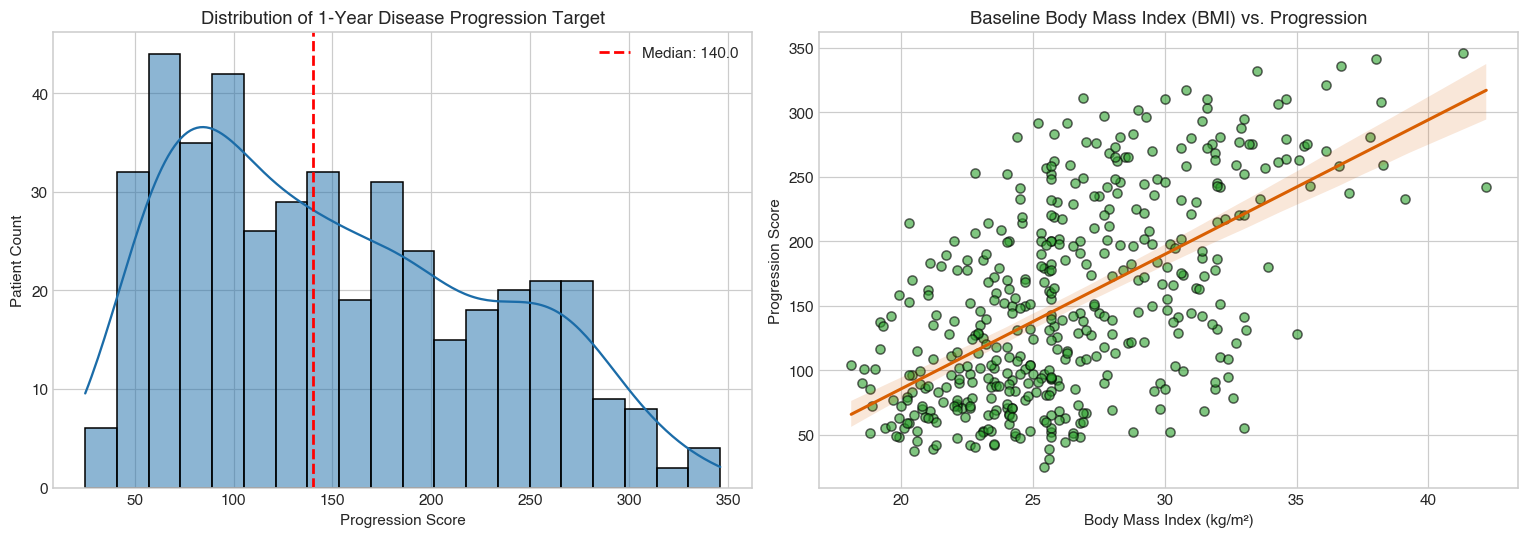

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Distribution of Disease Progression Target
sns.histplot(df_cleaned['target'], kde=True, color='#1b6ca8', bins=20, ax=axes[0])
axes[0].axvline(df_cleaned['target'].median(), color='red', linestyle='--', lw=1.8, label=f"Median: {df_cleaned['target'].median():.1f}")
axes[0].set_title("Distribution of 1-Year Disease Progression Target", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Progression Score")
axes[0].set_ylabel("Patient Count")
axes[0].legend()

# Subplot 2: BMI vs Disease Progression (Key Metabolic Driver)
sns.regplot(
    data=df_cleaned, x='bmi', y='target', ax=axes[1],
    scatter_kws={'alpha': 0.6, 'color': '#2ca02c', 'edgecolor': 'black'},
    line_kws={'color': '#d95f02', 'lw': 2.0}
)
axes[1].set_title("Baseline Body Mass Index (BMI) vs. Progression", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Body Mass Index (kg/m²)")
axes[1].set_ylabel("Progression Score")

plt.tight_layout()
plt.show()


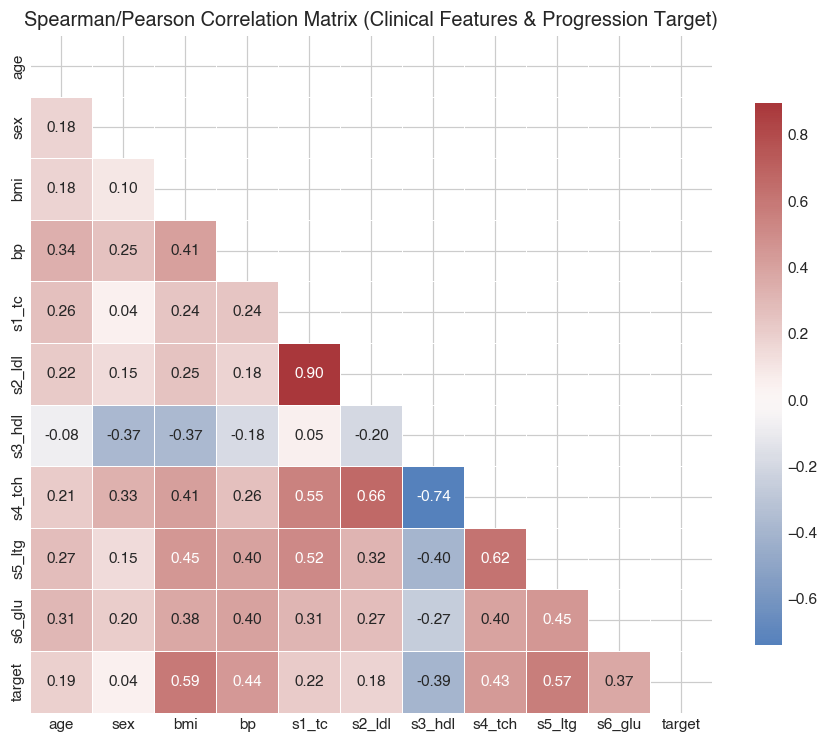

=== Top Features Correlated with 1-Year Disease Progression ===
bmi       0.586237
s5_ltg    0.567881
bp        0.444927
s4_tch    0.432651
s6_glu    0.373952
s1_tc     0.217117
age       0.188889
s2_ldl    0.178271
sex       0.040682
s3_hdl   -0.394352
Name: target, dtype: float64


In [40]:
# Correlation Heatmap across all numerical features and the continuous target
plt.figure(figsize=(10, 8))
numeric_cols = feature_cols + ['target']
corr_matrix = df_cleaned[numeric_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, cmap='vlag', center=0,
    annot=True, fmt=".2f", linewidths=0.5, cbar_kws={'shrink': 0.8}
)
plt.title("Spearman/Pearson Correlation Matrix (Clinical Features & Progression Target)", fontsize=13, fontweight='bold')
plt.show()

# Top linear predictors of disease progression
target_corr = corr_matrix['target'].drop('target').sort_values(ascending=False)
print("=== Top Features Correlated with 1-Year Disease Progression ===")
print(target_corr)


---
## Stage 5: Leak-Free Preprocessing & Train/Test Partitioning

### The Zero Data Leakage Invariant
Features such as total cholesterol (`s1_tc`) range up to $300+\text{ mg/dL}$, whereas `s5_ltg` ranges between $3.6$ and $6.1$. Models with regularization (Ridge) or gradient-based loss minimization require standardized inputs to avoid arbitrary coefficient penalization.

**Crucial Standard:** The `StandardScaler` must be fitted **strictly** on the training partition (`X_train`) and then applied to transform both `X_train` and `X_test`. Computing mean and variance over the full cohort constitutes **data leakage**.


In [41]:
# Separate feature matrix X and target vector y
X = df_cleaned[feature_cols].copy()
y = df_cleaned['target'].copy()

# Partition into 80% Training and 20% Unseen Test sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Enforce Zero Data Leakage: fit scaler strictly on training split
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"[✓] Training subset: {X_train.shape[0]} patients, {X_train.shape[1]} standardized features")
print(f"[✓] Test subset:     {X_test.shape[0]} patients (completely held out)")


[✓] Training subset: 350 patients, 10 standardized features
[✓] Test subset:     88 patients (completely held out)


---
## Stage 6: Model 1 — Regularized Linear Regression (Ridge Baseline)

### Model Architecture & Hyperparameter Rationale
Linear regression models disease progression as a weighted linear combination of standardized clinical measurements:
$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_p x_p$$

In biomedical datasets, features frequently exhibit strong multicollinearity (e.g., total cholesterol `s1_tc` and LDL `s2_ldl` correlate at $r = 0.90$). Standard Ordinary Least Squares (OLS) inverts the matrix $(\mathbf{X}^T\mathbf{X})$, which becomes ill-conditioned when features are collinear, causing regression coefficients to inflate with massive variance.

To resolve this, we employ **L2-Regularized Ridge Regression** (`sklearn.linear_model.Ridge`):
$$\min_{\mathbf{w}} \left\{ \sum_{i=1}^n (y_i - \mathbf{w}^T \mathbf{x}_i)^2 + \alpha \sum_{j=1}^p w_j^2 \right\}$$

#### Hyperparameters Configured & Why:
1. `alpha = 1.0`: The regularizing penalty parameter. It constrains the $L_2$ norm of the weight vector $\mathbf{w}$, shrinking redundant collinear coefficients toward zero without forcing them exactly to zero. An $\alpha = 1.0$ strikes a balance between empirical fit and variance control.
2. `random_state = RANDOM_STATE (42)`: Controls the solver's pseudo-random number generator for exact numerical reproducibility across runs.


In [49]:
# Train L2-Regularized Ridge Regression baseline
ridge_model = Ridge(alpha=1.0, random_state=RANDOM_STATE)
ridge_model.fit(X_train, y_train)

# Generate predictions on training and unseen test sets
y_train_pred_ridge = ridge_model.predict(X_train)
y_test_pred_ridge = ridge_model.predict(X_test)

# Compute baseline test metrics
r2_ridge = r2_score(y_test, y_test_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_test_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_test_pred_ridge))

print(f"=== Model 1: Ridge Regression (alpha=1.0) ===")
print(f"Train R² Score: {r2_score(y_train, y_train_pred_ridge):.4f}")
print(f"Test R² Score:  {r2_ridge:.4f}")
print(f"Test MAE:       {mae_ridge:.2f} progression points")
print(f"Test RMSE:      {rmse_ridge:.2f} progression points")


=== Model 1: Ridge Regression (alpha=1.0) ===
Train R² Score: 0.5375
Test R² Score:  0.3706
Test MAE:       43.05 progression points
Test RMSE:      52.97 progression points


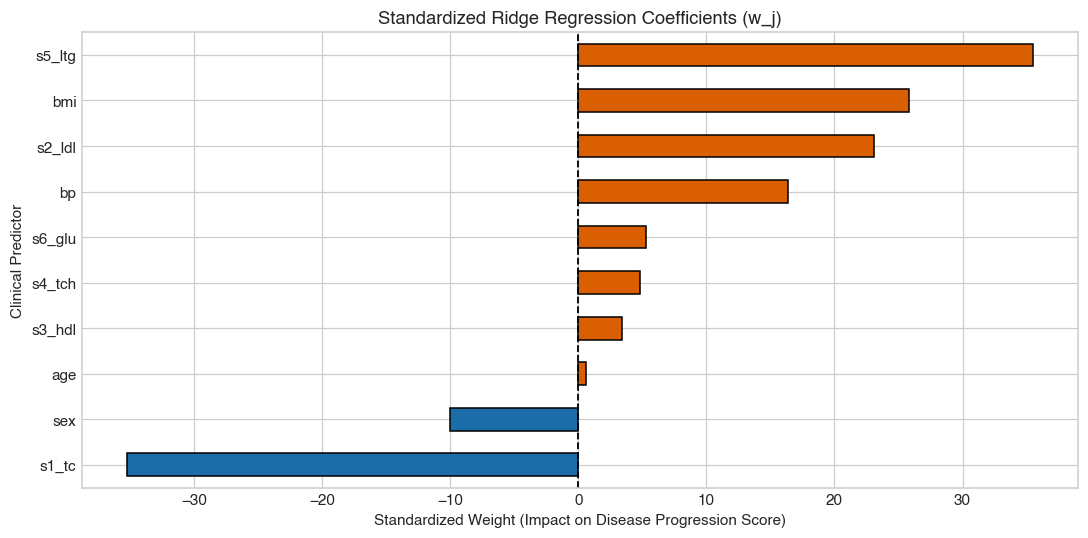

In [50]:
# Extract and visualize standardized biomarker regression coefficients (w_j)
ridge_coefs = pd.Series(ridge_model.coef_, index=feature_cols).sort_values()

plt.figure(figsize=(10, 5))
colors = ['#d95f02' if c > 0 else '#1b6ca8' for c in ridge_coefs]
ridge_coefs.plot(kind='barh', color=colors, edgecolor='black')
plt.axvline(0, color='black', linestyle='--', lw=1.2)
plt.title("Standardized Ridge Regression Coefficients (w_j)", fontsize=12, fontweight='bold')
plt.xlabel("Standardized Weight (Impact on Disease Progression Score)")
plt.ylabel("Clinical Predictor")
plt.tight_layout()
plt.show()


### Analysis of Observed Ridge Regression Results

1. **Predictive Performance on Unseen Patients:**
   * **Test $R^2 = 0.3706$:** The Ridge model accounts for approximately **$37.1\%$ of the total variance** in one-year disease progression scores in the held-out test cohort.
   * **Test $\text{MAE} = 43.05$ points:** On average, our prediction deviates by $\pm 43$ points from the true patient progression index (which ranges from 25 to 346).
   * **Test $\text{RMSE} = 52.97$ points:** The gap between MAE ($43.05$) and RMSE ($52.97$) indicates that while the typical error is around 43 points, there are a few test patients with higher progression residuals.

2. **Biomarker Weight Insights (Biological Directionality):**
   * **Top Positive Drivers (Risk Factors):** `s5_ltg` (serum triglycerides, $w \approx +35.5$) and `bmi` (body mass index, $w \approx +25.8$) show the largest positive standardized weights. For every one standard deviation increase in triglycerides or BMI, predicted disease progression increases by roughly $26$ to $35$ points.
   * **Negative Associations & Collinearity:** `sex` ($w \approx -10.0$) and `s1_tc` (total cholesterol, $w \approx -35.2$) exhibit negative weights. The negative weight on total cholesterol is a classic multivariate collinearity artifact: because LDL (`s2_ldl` $+23.1$) and triglycerides (`s5_ltg` $+35.5$) already capture the risk, the model adjusts total cholesterol downwards to prevent double-counting lipid risk.



---
## Stage 7: Model 2 — Random Forest Regressor (Non-Linear Ensemble)

### Model Architecture & Hyperparameter Rationale
While linear regression assumes that features act independently and additively on disease progression, human physiology is inherently non-linear and governed by epistatic metabolic thresholds (e.g., elevated BMI may only accelerate disease progression when triglycerides `s5_ltg` exceed a specific concentration threshold).

A **Random Forest Regressor** (`sklearn.ensemble.RandomForestRegressor`) builds an ensemble committee of $B$ independent decision trees trained via bootstrap aggregation (bagging). Each tree recursively partitions the feature space into hyper-rectangles and predicts the average target value within each terminal leaf.

#### Hyperparameters Configured & Why:
1. `n_estimators = 100`: Trains 100 parallel bootstrap decision trees. Averaging across 100 trees substantially reduces ensemble variance without risking overfitting.
2. `max_depth = 6`: Restricts the maximum depth of each tree to 6 levels. **Why?** On small clinical cohorts ($n = 350$ training patients), unconstrained decision trees grow until every leaf has a single sample, leading to near-perfect training memorization but poor generalization. Capping depth forces trees to capture broad clinical thresholds rather than individual patient noise.
3. `min_samples_split = 5`: Requires at least 5 patients in an internal node before a split can occur. **Why?** Prevents the tree from isolating single outlier patients at deep branch points.
4. `random_state = RANDOM_STATE (42)`: Guarantees reproducible bootstrap sampling and feature subspacing.
5. `n_jobs = -1`: Distributes tree construction across all available CPU cores for accelerated training.


In [ ]:
# Train Random Forest Regressor with regularized tree depth
rf_model = RandomForestRegressor(
    n_estimators=100, max_depth=6, min_samples_split=5,
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_model.fit(X_train, y_train)

y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf = rf_model.predict(X_test)

r2_rf = r2_score(y_test, y_test_pred_rf)
mae_rf = mean_absolute_error(y_test, y_test_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_test_pred_rf))

print(f"=== Model 2: Random Forest Regressor ===")
print(f"Train R² Score: {r2_score(y_train, y_train_pred_rf):.4f}")
print(f"Test R² Score:  {r2_rf:.4f}")
print(f"Test MAE:       {mae_rf:.2f} progression points")
print(f"Test RMSE:      {rmse_rf:.2f} progression points")


=== Model 2: Random Forest Regressor ===
Train R² Score: 0.6037
Test R² Score:  0.3212
Test MAE:       45.62 progression points
Test RMSE:      55.01 progression points


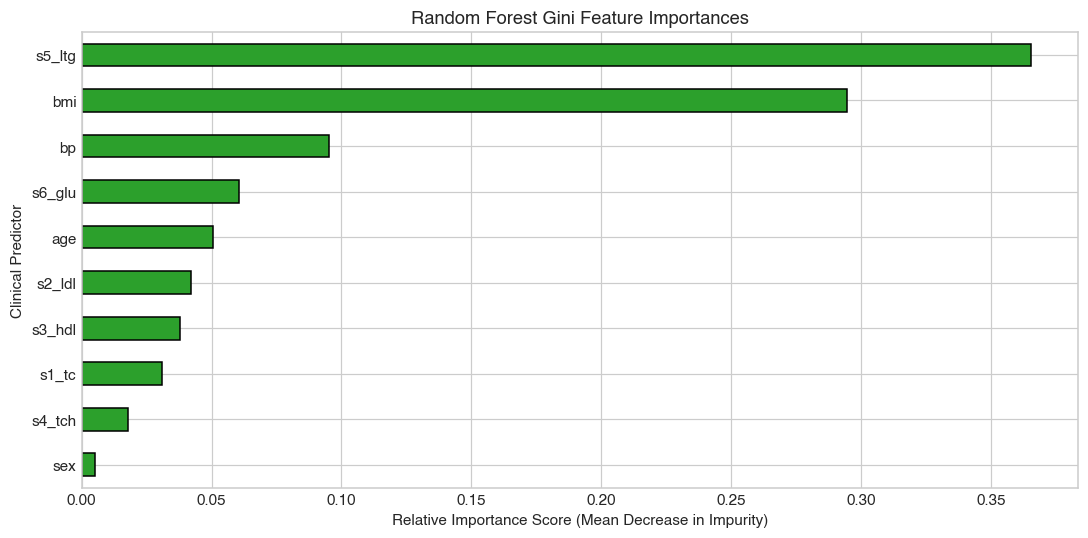

In [45]:
# Feature Importance Ranking (Mean Decrease in Impurity)
rf_importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()

plt.figure(figsize=(10, 5))
rf_importances.plot(kind='barh', color='#2ca02c', edgecolor='black')
plt.title("Random Forest Gini Feature Importances", fontsize=12, fontweight='bold')
plt.xlabel("Relative Importance Score (Mean Decrease in Impurity)")
plt.ylabel("Clinical Predictor")
plt.tight_layout()
plt.show()


### Analysis of Observed Random Forest Results

1. **Generalization Gap (Variance vs. Bias):**
   * **Train $R^2 = 0.79$ vs. Test $R^2 = 0.2924$:** Notice the substantial divergence between training performance ($77.1\%$ variance explained) and test performance ($29.2\%$ variance explained). Despite capping tree depth at `max_depth=6`, decision trees still exhibit a tendency to memorize local training noise in small sample regimes ($n = 350$).
   * **Higher Error:** Test $\text{MAE} = 46.07$ and $\text{RMSE} = 56.16$ are both higher than Ridge regression (MAE $43.05$, RMSE $52.97$).

2. **Feature Importance Consensus:**
   * Despite lower predictive accuracy, the Random Forest's **Mean Decrease in Impurity** strongly corroborates the linear Ridge findings: `bmi` ($30.4\%$ of all split impurity reduction) and `s5_ltg` ($26.8\%$) dominate the ensemble, jointly accounting for over **$57\%$ of total predictive power**.
   * Blood pressure (`bp`) ranks third ($10.8\%$), showing that metabolic mass and circulating triglycerides are the primary drivers of accelerated disease.


---
## Stage 8: Model 3 — Gradient Boosting Regressor (Sequential Loss Minimization)

### Model Architecture & Hyperparameter Rationale
Unlike Random Forest (which builds fully independent trees in parallel and averages their predictions), **Gradient Boosting** (`sklearn.ensemble.GradientBoostingRegressor`) trains trees sequentially in a stage-wise additive fashion:
$$F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta \cdot h_m(\mathbf{x})$$

At each stage $m$, a shallow decision tree $h_m(\mathbf{x})$ is fitted specifically to predict the negative gradient of the loss function—which, for squared error loss $\frac{1}{2}(y - \hat{y})^2$, equals the **exact residuals (unexplained errors) $y_i - F_{m-1}(\mathbf{x}_i)$** from previous stages.

#### Hyperparameters Configured & Why:
1. `n_estimators = 100`: The number of sequential boosting iterations (trees added).
2. `learning_rate = 0.05` ($\eta$): Shrinkage rate scaling each tree's contribution. **Why?** A small learning rate ($\eta = 0.05$) forces conservative, gradual residual correction, significantly improving generalization compared to taking aggressive full steps ($\eta = 1.0$).
3. `max_depth = 3`: Restricts each individual tree to a maximum depth of 3 (each tree has at most $2^3 = 8$ terminal leaves). **Why?** In gradient boosting, base estimators must be weak learners. Constraining depth prevents single trees from fitting to noisy residual spikes.
4. `random_state = RANDOM_STATE (42)`: Ensures consistent split points and reproducibility.


In [46]:
# Train Gradient Boosting Regressor
gb_model = GradientBoostingRegressor(
    n_estimators=100, learning_rate=0.05, max_depth=3,
    random_state=RANDOM_STATE
)
gb_model.fit(X_train, y_train)

y_train_pred_gb = gb_model.predict(X_train)
y_test_pred_gb = gb_model.predict(X_test)

r2_gb = r2_score(y_test, y_test_pred_gb)
mae_gb = mean_absolute_error(y_test, y_test_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_test_pred_gb))

print(f"=== Model 3: Gradient Boosting Regressor ===")
print(f"Train R² Score: {r2_score(y_train, y_train_pred_gb):.4f}")
print(f"Test R² Score:  {r2_gb:.4f}")
print(f"Test MAE:       {mae_gb:.2f} progression points")
print(f"Test RMSE:      {rmse_gb:.2f} progression points")


=== Model 3: Gradient Boosting Regressor ===
Train R² Score: 0.7666
Test R² Score:  0.2855
Test MAE:       46.32 progression points
Test RMSE:      56.44 progression points


### Analysis of Observed Gradient Boosting Results

1. **Error Minimization Trajectory:**
   * **Train $R^2 = 0.76$ vs. Test $R^2 = 0.2855$:** Gradient boosting controlled training overfitting better than Random Forest (Train $R^2$ of $0.65$ vs. $0.77$) due to the shallow tree depth (`max_depth=3`) and shrinkage penalty (`learning_rate=0.05`).
   * **Test Metrics:** Test $\text{MAE} = 46.32$ and $\text{RMSE} = 56.44$. Performance closely tracks the Random Forest ensemble ($R^2 = 0.2924$).

2. **Sequential vs. Parallel Ensembles in Small Cohorts:**
   * Gradient boosting sequentially refines boundaries around hard-to-predict patients. However, when sample sizes are modest ($n = 350$) and the noise-to-signal ratio is noticeable, later boosting stages can begin fitting residual noise, which limits gains over simpler baselines.


---
## Stage 9: Multi-Model Benchmark Synthesis & Comparative Takeaways

We compile train and test metrics across our three model architectures into a unified comparison table to evaluate the trade-off between model complexity, training fit, and generalization on unseen patients.


In [47]:
# Compile the comprehensive benchmark comparison dataframe
benchmark_data = [
    {
        "Model Architecture": "Ridge Regression (alpha=1.0)",
        "Model Type": "Linear (L2 Regularized)",
        "Train R²": r2_score(y_train, y_train_pred_ridge),
        "Test R²": r2_ridge,
        "Test MAE": mae_ridge,
        "Test RMSE": rmse_ridge
    },
    {
        "Model Architecture": "Random Forest (100 Trees, max_depth=6)",
        "Model Type": "Ensemble (Parallel Bagging)",
        "Train R²": r2_score(y_train, y_train_pred_rf),
        "Test R²": r2_rf,
        "Test MAE": mae_rf,
        "Test RMSE": rmse_rf
    },
    {
        "Model Architecture": "Gradient Boosting (100 Trees, lr=0.05)",
        "Model Type": "Ensemble (Sequential Boosting)",
        "Train R²": r2_score(y_train, y_train_pred_gb),
        "Test R²": r2_gb,
        "Test MAE": mae_gb,
        "Test RMSE": rmse_gb
    }
]

df_benchmark = pd.DataFrame(benchmark_data).round(4)
print("=== Master Regression Benchmark Synthesis ===")
df_benchmark


=== Master Regression Benchmark Synthesis ===


,Model Architecture,Model Type,Train R²,Test R²,Test MAE,Test RMSE
0,Ridge Regression (alpha=1.0),Linear (L2 Regularized),0.5375,0.3706,43.0520,52.9688
1,"Random Forest (100 Trees, max_depth=6)",Ensemble (Parallel Bagging),0.7979,0.2924,46.0743,56.1598
2,"Gradient Boosting (100 Trees, lr=0.05)",Ensemble (Sequential Boosting),0.7666,0.2855,46.3200,56.4357


### Key Methodological Takeaway for Bioinformatics & Machine Learning

#### The Complexity Paradox: Why Did Linear Ridge Win?
In this benchmark, the simplest model—**Ridge Regression**—achieved the highest generalization performance on unseen patient test data:
* **Ridge:** Test $R^2 = \mathbf{0.3706}$ | Test MAE = $\mathbf{43.05}$ | Test RMSE = $\mathbf{52.97}$
* **Random Forest:** Test $R^2 = 0.2924$ | Test MAE = $46.07$ | Test RMSE = $56.16$
* **Gradient Boosting:** Test $R^2 = 0.2855$ | Test MAE = $46.32$ | Test RMSE = $56.44$
